In [10]:
import sys
sys.path.append("..")

import pandas as pd
from Src.Core.config import DATA_PROCESSED_DIR
from Src.Data.loader import URLDataLoader
from Src.Features import (
    LexicalFeatureExtractor,
    HostingFeatureExtractor,
    FeatureExtractor,
)
from Src.Features.extractor import _row_to_parsed

In [11]:
loader = URLDataLoader()
df_parsed = loader.load_parsed()
print(f"Tổng số URL đã nạp: {len(df_parsed)}")
df_parsed.head(3)

d:\ML trong phát hiện URL Phishing\Notebooks\..\Src\Data\loader.py:13: DtypeWarning: Columns (0: path, 1: query) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(self.data_dir / filename)


Tổng số URL đã nạp: 201040


,url,label,scheme,netloc,host,port,path,query,subdomain,domain,suffix,registered_domain,main_tld,is_private_suffix
0,https://www.atelierozmoz.be,0,https,www.atelierozmoz.be,www.atelierozmoz.be,NaN,NaN,NaN,www,atelierozmoz,be,atelierozmoz.be,be,False
1,https://www.diemon.com,0,https,www.diemon.com,www.diemon.com,NaN,NaN,NaN,www,diemon,com,diemon.com,com,False
2,https://www.wausauschools.org,0,https,www.wausauschools.org,www.wausauschools.org,NaN,NaN,NaN,www,wausauschools,org,wausauschools.org,org,False


In [12]:
lexical_extractor = LexicalFeatureExtractor()

sample_rows = df_parsed.head(5)
sample_lexical = [lexical_extractor.extract(_row_to_parsed(row)) for _, row in sample_rows.iterrows()]
df_sample_lexical = pd.DataFrame(sample_lexical)

print(f"Số lượng đặc trưng từ vựng: {df_sample_lexical.shape[1]}")
df_sample_lexical

Số lượng đặc trưng từ vựng: 33


,url_length,url_letters_count,url_letters_ratio,url_digits_count,url_digits_ratio,url_special_chars_count,url_special_chars_ratio,url_uppercase_ratio,url_char_entropy,url_num_dots,...,path_longest_segment_len,path_entropy,path_sensitive_words_count,query_length,query_num_params,has_embedded_url,has_fragment,count_percent_encoding,has_double_encoding,query_sensitive_words_count
0,27,22,0.8148,0,0.0,5,0.1852,0.0,3.9303,2,...,0,0.0,0,0,0,0,0,0,0,0
1,22,17,0.7727,0,0.0,5,0.2273,0.0,3.7888,2,...,0,0.0,0,0,0,0,0,0,0,0
2,29,24,0.8276,0,0.0,5,0.1724,0.0,3.7285,2,...,0,0.0,0,0,0,0,0,0,0,0
3,25,20,0.8000,0,0.0,5,0.2000,0.0,3.7337,2,...,0,0.0,0,0,0,0,0,0,0,0
4,26,21,0.8077,0,0.0,5,0.1923,0.0,3.9022,2,...,0,0.0,0,0,0,0,0,0,0,0


In [13]:
hosting_extractor = HostingFeatureExtractor()

sample_hosting = [hosting_extractor.extract(_row_to_parsed(row)) for _, row in sample_rows.iterrows()]
df_sample_hosting = pd.DataFrame(sample_hosting)

print(f"Số lượng đặc trưng máy chủ: {df_sample_hosting.shape[1]}")
df_sample_hosting

Số lượng đặc trưng máy chủ: 17


,is_ip_host,is_hex_octal_dword_ip,is_non_standard_port,domain_length,domain_dots_count,domain_has_hyphen,domain_digits_count,domain_entropy,subdomain_levels,subdomain_length,registered_domain_len,is_risky_tld,is_free_hosting,has_punycode,is_url_shortener,brand_in_subdomain,domain_sensitive_words_count
0,0,0,0,19,2,0,0,3.0850,1,3,15,0,0,0,0,0,0
1,0,0,0,14,2,0,0,2.5850,1,3,10,0,0,0,0,0,0
2,0,0,0,21,2,0,0,2.8731,1,3,17,0,0,0,0,0,0
3,0,0,0,17,2,0,0,2.5033,1,3,13,0,0,0,0,0,0
4,0,0,0,18,2,0,0,3.1219,1,3,14,0,0,0,0,0,0


In [14]:
extractor = FeatureExtractor()
print(f"Bắt đầu trích xuất {len(extractor.feature_names)} đặc trưng trên {len(df_parsed)} URL...")

df_features = extractor.extract_batch(df_parsed)

df_features.head(3)

Bắt đầu trích xuất 50 đặc trưng trên 201040 URL...


,url_length,url_letters_count,url_letters_ratio,url_digits_count,url_digits_ratio,url_special_chars_count,url_special_chars_ratio,url_uppercase_ratio,url_char_entropy,url_num_dots,...,domain_entropy,subdomain_levels,subdomain_length,registered_domain_len,is_risky_tld,is_free_hosting,has_punycode,is_url_shortener,brand_in_subdomain,domain_sensitive_words_count
0,27,22,0.8148,0,0.0,5,0.1852,0.0,3.9303,2,...,3.0850,1,3,15,0,0,0,0,0,0
1,22,17,0.7727,0,0.0,5,0.2273,0.0,3.7888,2,...,2.5850,1,3,10,0,0,0,0,0,0
2,29,24,0.8276,0,0.0,5,0.1724,0.0,3.7285,2,...,2.8731,1,3,17,0,0,0,0,0,0


In [15]:
# 1. Thêm metadata 
if "url" not in df_features.columns:
    df_features.insert(0, "url", df_parsed["url"].values)
if "registered_domain" not in df_features.columns:
    df_features.insert(1, "registered_domain", df_parsed["registered_domain"].values)

# 2. Ghép nhãn (0: Lành tính, 1: Phishing)
df_features["label"] = df_parsed["label"].values

# 3. Kiểm tra giá trị thiếu (NaN / Null)
total_nans = df_features.isna().sum().sum()
assert total_nans == 0, f"Phát hiện {total_nans} giá trị NaN!"

print("\nPhân phối nhãn dữ liệu (0: Lành tính, 1: Phishing):")
print(df_features["label"].value_counts(normalize=True))
df_features.head(3)



Phân phối nhãn dữ liệu (0: Lành tính, 1: Phishing):
label
0    0.5
1    0.5
Name: proportion, dtype: float64


,url,registered_domain,url_length,url_letters_count,url_letters_ratio,url_digits_count,url_digits_ratio,url_special_chars_count,url_special_chars_ratio,url_uppercase_ratio,...,subdomain_levels,subdomain_length,registered_domain_len,is_risky_tld,is_free_hosting,has_punycode,is_url_shortener,brand_in_subdomain,domain_sensitive_words_count,label
0,https://www.atelierozmoz.be,atelierozmoz.be,27,22,0.8148,0,0.0,5,0.1852,0.0,...,1,3,15,0,0,0,0,0,0,0
1,https://www.diemon.com,diemon.com,22,17,0.7727,0,0.0,5,0.2273,0.0,...,1,3,10,0,0,0,0,0,0,0
2,https://www.wausauschools.org,wausauschools.org,29,24,0.8276,0,0.0,5,0.1724,0.0,...,1,3,17,0,0,0,0,0,0,0


In [16]:
output_file = DATA_PROCESSED_DIR / "dataset.csv"
df_features.to_csv(output_file, index=False)
print(f"Đã lưu thành công ma trận đặc trưng tại: {output_file}")

Đã lưu thành công ma trận đặc trưng tại: D:\ML trong phát hiện URL Phishing\Data\Processed\dataset.csv


In [17]:
# Nhập URL bất kỳ để kiểm tra trích xuất 50 đặc trưng 
test_benign = "https://www.google.com/search?q=machine+learning"
test_phishing = "http://vietcombank.login-secure.pages.dev:8080/auth/verify?token=123"

feats_benign = extractor.extract_one(test_benign)
feats_phishing = extractor.extract_one(test_phishing)

# Hiển thị bảng đối chứng 50 đặc trưng giữa 2 URL
df_demo = pd.DataFrame(
    [feats_benign, feats_phishing],
    index=["Lành tính", "Lừa đảo"]
).T

print(f"Tổng số đặc trưng: {len(df_demo)}")
df_demo


Tổng số đặc trưng: 50


,Lành tính,Lừa đảo
url_length,48.0000,68.0000
url_letters_count,39.0000,49.0000
url_letters_ratio,0.8125,0.7206
url_digits_count,0.0000,7.0000
url_digits_ratio,0.0000,0.1029
url_special_chars_count,9.0000,12.0000
url_special_chars_ratio,0.1875,0.1765
url_uppercase_ratio,0.0000,0.0000
url_char_entropy,4.3341,4.7670
url_num_dots,2.0000,3.0000


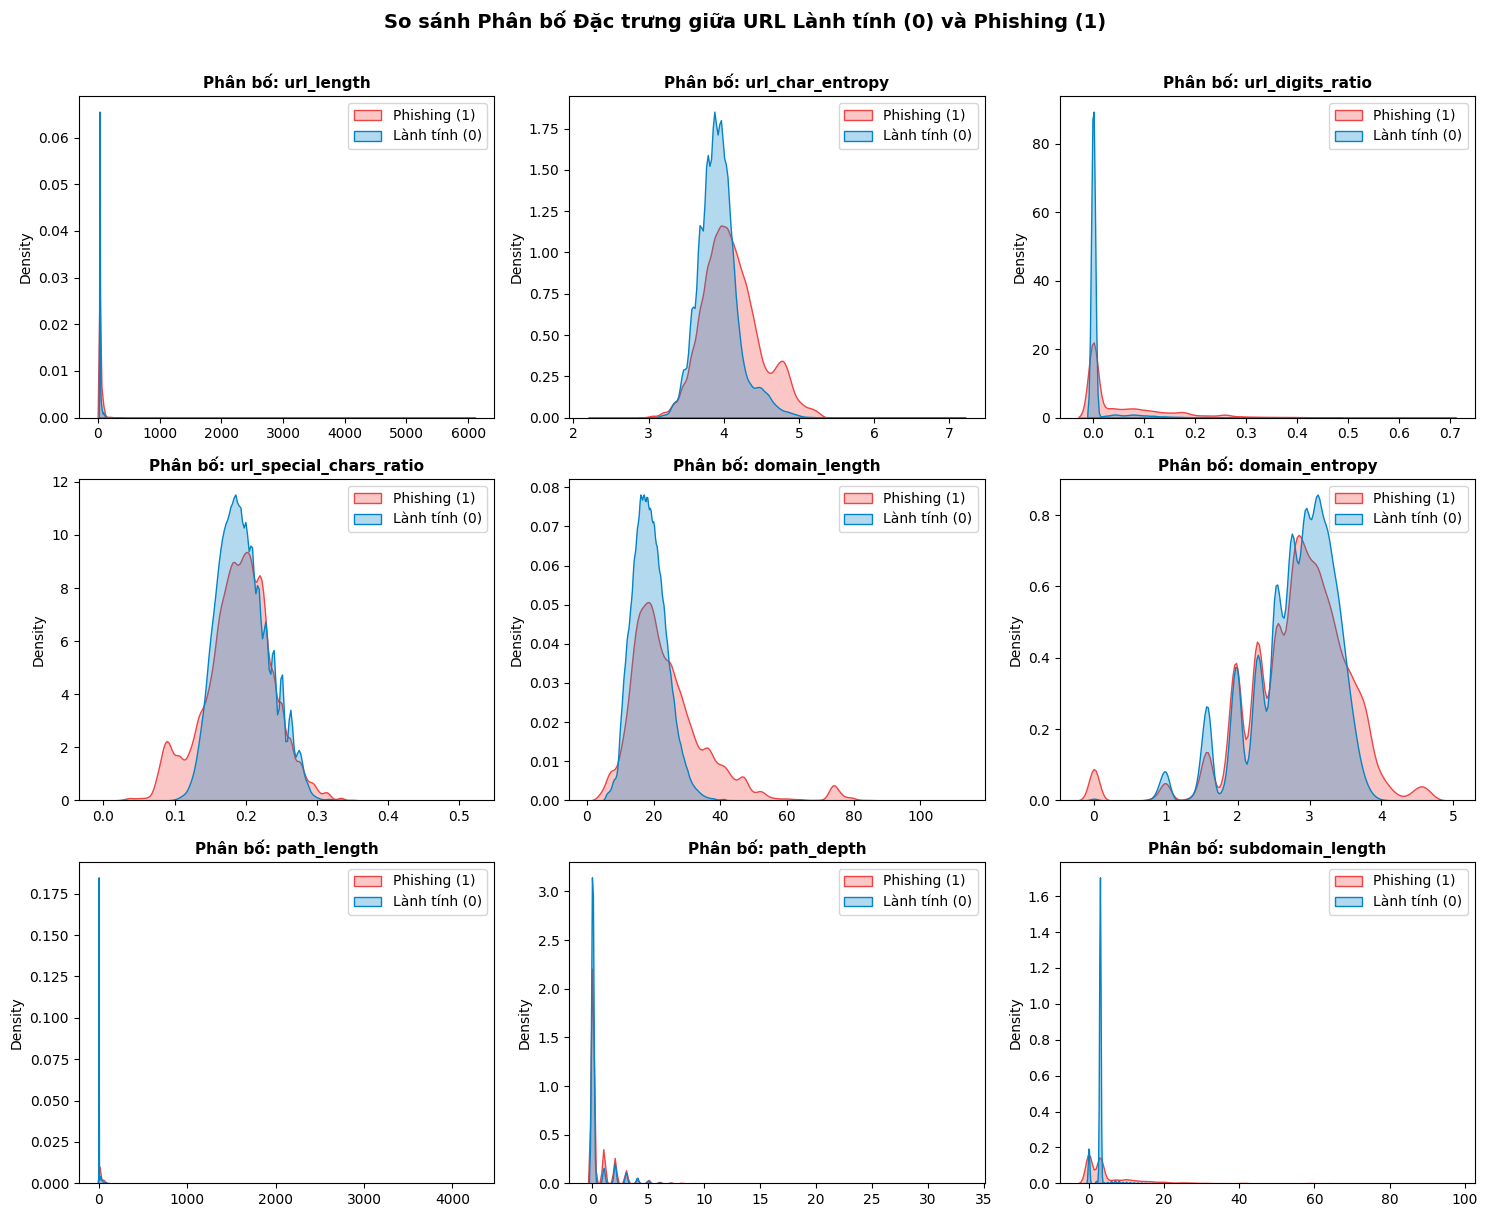

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Chọn 9 đặc trưng số học liên tục tiêu biểu
features_to_plot = [
    "url_length", "url_char_entropy", "url_digits_ratio",
    "url_special_chars_ratio", "domain_length", "domain_entropy",
    "path_length", "path_depth", "subdomain_length"
]

df_plot = df_features[features_to_plot].copy()
df_plot["label_name"] = df_features["label"].map({0: "Lành tính (0)", 1: "Phishing (1)"})

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.kdeplot(
        data=df_plot, x=col, hue="label_name",
        common_norm=False, fill=True, alpha=0.3,
        palette={"Lành tính (0)": "#0284c7", "Phishing (1)": "#ef4444"}, ax=axes[i]
    )
    axes[i].set_title(f"Phân bố: {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")

plt.suptitle("So sánh Phân bố Đặc trưng giữa URL Lành tính (0) và Phishing (1)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()
